In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx
from tqdm.auto import tqdm
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from neo4j import GraphDatabase

URI  = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "PASSWORDMU")        # ganti
DB   = "uts-graf-sainsdata"

df = pd.read_csv("data/events.csv")
t = pd.to_datetime(df["timestamp"], unit="ms")
print(t.min(), "->", t.max())
print(t.dt.to_period("W").value_counts().sort_index())

2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000
timestamp
2015-04-27/2015-05-03     13683
2015-05-04/2015-05-10    133775
2015-05-11/2015-05-17    148861
2015-05-18/2015-05-24    152514
2015-05-25/2015-05-31    141819
2015-06-01/2015-06-07    146445
2015-06-08/2015-06-14    131852
2015-06-15/2015-06-21    145976
2015-06-22/2015-06-28    141688
2015-06-29/2015-07-05    139233
2015-07-06/2015-07-12    161845
2015-07-13/2015-07-19    152243
2015-07-20/2015-07-26    175437
2015-07-27/2015-08-02    144337
2015-08-03/2015-08-09    128559
2015-08-10/2015-08-16    120763
2015-08-17/2015-08-23    126924
2015-08-24/2015-08-30    127810
2015-08-31/2015-09-06    119057
2015-09-07/2015-09-13    138789
2015-09-14/2015-09-20     64491
Freq: W-SUN, Name: count, dtype: int64


In [2]:
def to_ms(s):
    return int(pd.Timestamp(s, tz="UTC").timestamp() * 1000)

# P1: 18 Juni 2015 s.d. 17 Juli 2015 (inklusif sampai 23:59:59.999)
# P2: 18 Juli 2015 s.d. 18 September 2015 (inklusif sampai 23:59:59.999)
P1_START, P1_END = to_ms("2015-06-18"), to_ms("2015-07-18") - 1
P2_START, P2_END = to_ms("2015-07-18"), to_ms("2015-09-19") - 1
print("ISI KE GOOGLE FORM:", P1_START, P1_END, P2_START, P2_END)

p1 = df[(df.timestamp >= P1_START) & (df.timestamp <= P1_END)]
p2 = df[(df.timestamp >= P2_START) & (df.timestamp <= P2_END)]
p1.to_csv("data/events_p1.csv", index=False)
p2.to_csv("data/events_p2.csv", index=False)

print(len(p1), len(p2))
print(p1.event.value_counts())
print("User di P1 & P2:", len(set(p1.visitorid) & set(p2.visitorid)))

ISI KE GOOGLE FORM: 1434585600000 1437177599999 1437177600000 1442620799999
636862 1179460
event
view           615960
addtocart       15668
transaction      5234
Name: count, dtype: int64
User di P1 & P2: 20084


# UTS Graf Sains Data — Rekomendasi dengan Neo4j dan RetailRocket

**Nama:** Desnanty Ratna Aulia
**NIM:** 24031554163
**Program Studi:** S1 Sains Data, Universitas Negeri Surabaya

**Periode yang dipilih:**
- P1 (training): 18 Juni 2015 s.d. 17 Juli 2015 → 1434585600000 s.d. 1437177599999
- P2 (testing): 18 Juli 2015 s.d. 18 September 2015 → 1437177600000 s.d. 1442620799999

Periode ditentukan dari tanggal lahir (hari ke-18) agar kombinasi periode unik di kelas. Total rentang 3 bulan: P1 1 bulan, P2 2 bulan.

Alur: filter data → impor ke Neo4j → komposisi subgraph → VSM User dan Item → pilih proyeksi → similarity → KNN → Hit@5 dan NDCG@5.

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx
from getpass import getpass
from tqdm.auto import tqdm
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from neo4j import GraphDatabase

URI  = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", getpass("Password Neo4j: "))   # password diketik di kotak input
DB   = "uts-graf-sainsdata"

Password Neo4j:  ········


In [4]:
df = pd.read_csv("data/events.csv")
t = pd.to_datetime(df["timestamp"], unit="ms")
print(t.min(), "->", t.max())
print(t.dt.to_period("W").value_counts().sort_index())

2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000
timestamp
2015-04-27/2015-05-03     13683
2015-05-04/2015-05-10    133775
2015-05-11/2015-05-17    148861
2015-05-18/2015-05-24    152514
2015-05-25/2015-05-31    141819
2015-06-01/2015-06-07    146445
2015-06-08/2015-06-14    131852
2015-06-15/2015-06-21    145976
2015-06-22/2015-06-28    141688
2015-06-29/2015-07-05    139233
2015-07-06/2015-07-12    161845
2015-07-13/2015-07-19    152243
2015-07-20/2015-07-26    175437
2015-07-27/2015-08-02    144337
2015-08-03/2015-08-09    128559
2015-08-10/2015-08-16    120763
2015-08-17/2015-08-23    126924
2015-08-24/2015-08-30    127810
2015-08-31/2015-09-06    119057
2015-09-07/2015-09-13    138789
2015-09-14/2015-09-20     64491
Freq: W-SUN, Name: count, dtype: int64


In [5]:
def to_ms(s):
    return int(pd.Timestamp(s, tz="UTC").timestamp() * 1000)

# P1: 18 Juni 2015 s.d. 17 Juli 2015 (inklusif sampai 23:59:59.999)
# P2: 18 Juli 2015 s.d. 18 September 2015 (inklusif sampai 23:59:59.999)
P1_START, P1_END = to_ms("2015-06-18"), to_ms("2015-07-18") - 1
P2_START, P2_END = to_ms("2015-07-18"), to_ms("2015-09-19") - 1
print("ISI KE GOOGLE FORM:", P1_START, P1_END, P2_START, P2_END)

p1 = df[(df.timestamp >= P1_START) & (df.timestamp <= P1_END)]
p2 = df[(df.timestamp >= P2_START) & (df.timestamp <= P2_END)]
p1.to_csv("data/events_p1.csv", index=False)
p2.to_csv("data/events_p2.csv", index=False)

print(len(p1), len(p2))
print(p1.event.value_counts())
print("User di P1 & P2:", len(set(p1.visitorid) & set(p2.visitorid)))

ISI KE GOOGLE FORM: 1434585600000 1437177599999 1437177600000 1442620799999
636862 1179460
event
view           615960
addtocart       15668
transaction      5234
Name: count, dtype: int64
User di P1 & P2: 20084


## 1. Wrangling dan filter periode
Filter diterapkan pada kolom `timestamp` (milidetik) dengan batas bawah dan batas atas sama-sama inklusif (`>=` dan `<=`). Batas akhir ditulis 1 milidetik sebelum tengah malam hari berikutnya, sehingga P1 mencakup seluruh tanggal 17 Juli 2015 dan P2 mencakup seluruh tanggal 18 September 2015. P1 dan P2 tidak beririsan. P1 dipakai membangun graf (training), P2 dipakai sebagai kunci jawaban evaluasi (testing). Rentang data hanya Mei-Sep 2015, sehingga contoh periode 2023/2024 di soal tidak dapat dipakai. Hasil disimpan ke events_p1.csv dan events_p2.csv.

Jumlah baris P1 = 636.862, P2 = 1.179.460; user yang muncul di kedua periode = 20.084.

## 2. Impor data ke Neo4j
Data P1 diimpor ke Neo4j lewat Python driver. Kode contoh dimodifikasi: argparse diganti variabel biasa dan blok CALL...UNION ALL dipecah jadi tiga query (satu per jenis event). Impor per batch 10.000 baris dengan UNWIND. Simpul dibuat dengan MERGE (didukung constraint unik) agar tidak duplikat, relasi dibuat dengan CREATE: view -> VIEWED, addtocart -> ADDED_TO_CART, transaction -> BOUGHT.

In [6]:
driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Terhubung ke Neo4j")

def q(cypher, **params):
    with driver.session(database=DB) as s:
        return s.run(cypher, **params).data()

def create_constraints():
    q("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    q("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_events(data, rel, with_tx=False, batch_size=10000):
    props = "timestamp: row.timestamp" + (", transactionId: row.transactionid" if with_tx else "")
    cypher = f"""
    UNWIND $batch AS row
    MERGE (v:Visitor {{visitorId: row.visitorid}})
    MERGE (i:Item {{itemId: row.itemid}})
    CREATE (v)-[:{rel} {{{props}}}]->(i)
    """
    def work(tx, chunk):
        tx.run(cypher, batch=chunk).consume()
    with driver.session(database=DB) as s:
        for k in tqdm(range(0, len(data), batch_size), desc=rel):
            s.execute_write(work, data.iloc[k:k+batch_size].to_dict("records"))

Terhubung ke Neo4j


In [8]:
while True:
    r = q("MATCH (n) WITH n LIMIT 20000 DETACH DELETE n RETURN count(*) AS c")
    if r[0]["c"] == 0:
        break       
create_constraints()
cols = ["timestamp", "visitorid", "itemid"]
import_events(p1[p1.event == "view"][cols], "VIEWED")
import_events(p1[p1.event == "addtocart"][cols], "ADDED_TO_CART")
tx = p1[p1.event == "transaction"][cols + ["transactionid"]].astype({"transactionid": "int64"})
import_events(tx, "BOUGHT", with_tx=True)
print("Impor selesai")

VIEWED:   0%|          | 0/62 [00:00<?, ?it/s]

ADDED_TO_CART:   0%|          | 0/2 [00:00<?, ?it/s]

BOUGHT:   0%|          | 0/1 [00:00<?, ?it/s]

Impor selesai


In [9]:
print(pd.DataFrame(q("MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah")))
print(pd.DataFrame(q("MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(*) AS jumlah")))

  jenis_simpul  jumlah
0      Visitor  338157
1         Item  122288
    jenis_relasi  jumlah
0         VIEWED  615960
1  ADDED_TO_CART   15668
2         BOUGHT    5234


## 3. Komposisi subgraph
- `MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah` : ambil semua simpul, kelompokkan per label, hitung jumlahnya (seperti GROUP BY).
- `MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(*) AS jumlah` : ambil semua relasi, kelompokkan per jenis, hitung jumlahnya.

Hasil: Visitor 338.157 dan Item 122.288; VIEWED 615.960, ADDED_TO_CART 15.668, BOUGHT 5.234 (total 636.862 = jumlah baris P1).

In [10]:
W = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}
e = pd.DataFrame(q("MATCH (v:Visitor)-[r]->(i:Item) RETURN v.visitorId AS u, i.itemId AS i, type(r) AS rel, count(*) AS n"))
e["w"] = e["n"] * e["rel"].map(W)
agg = e.groupby(["u", "i"], as_index=False)["w"].sum()

u_ids, u_pos = np.unique(agg["u"], return_inverse=True)
i_ids, i_pos = np.unique(agg["i"], return_inverse=True)
M = csr_matrix((agg["w"].to_numpy(float), (u_pos, i_pos)), shape=(len(u_ids), len(i_ids)))

n_u, n_i = M.shape
deg_u = np.diff(M.indptr)               # jumlah item berbeda per user
deg_i = np.diff(M.tocsc().indptr)       # jumlah user berbeda per item
print("VSM User:", M.shape, "| VSM Item:", M.T.shape)
print("nilai non-nol:", M.nnz, "| density:", M.nnz / (n_u * n_i))
print(pd.Series(deg_u).describe())
print(pd.Series(deg_i).describe())
print("user dengan hanya 1 item:", (deg_u == 1).mean())

VSM User: (338157, 122288) | VSM Item: (122288, 338157)
nilai non-nol: 498698 | density: 1.2059669399173624e-05
count    338157.000000
mean          1.474753
std           6.123524
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max        1685.000000
dtype: float64
count    122288.000000
mean          4.078062
std           8.841191
min           1.000000
25%           1.000000
50%           2.000000
75%           4.000000
max         480.000000
dtype: float64
user dengan hanya 1 item: 0.8169548464174925


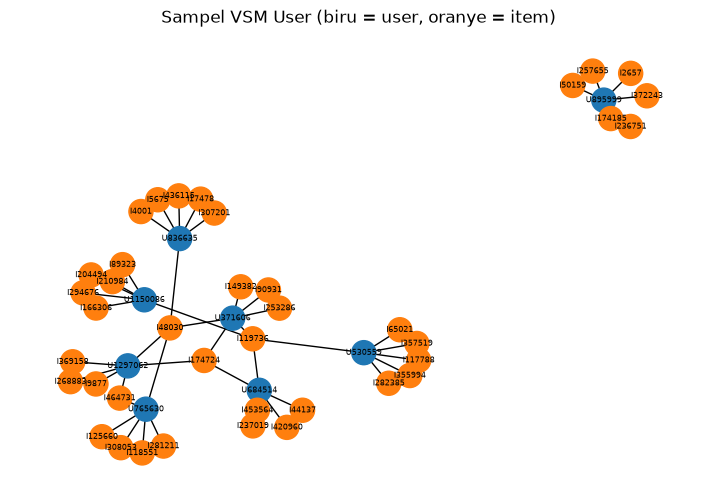

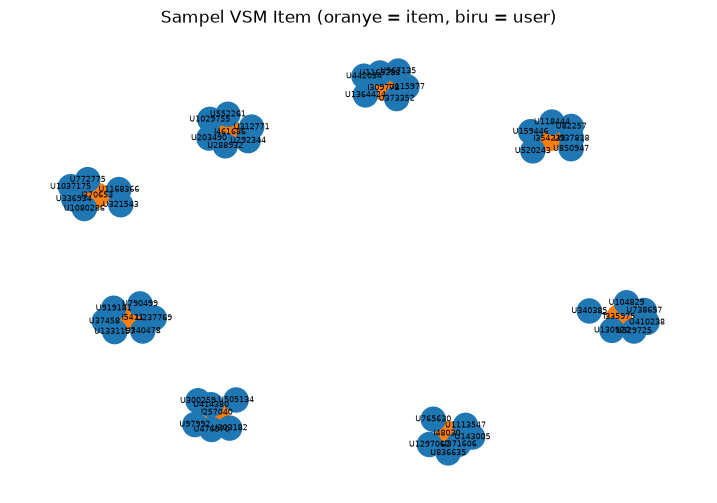

In [11]:
def sample_graph(center, n=8, per=6):
    G = nx.Graph()
    if center == "user":
        for a in np.argsort(-deg_u)[:n]:
            row = M[a]
            for j in row.indices[np.argsort(-row.data)[:per]]:
                G.add_edge(f"U{u_ids[a]}", f"I{i_ids[j]}")
    else:
        Mc = M.tocsc()
        for a in np.argsort(-deg_i)[:n]:
            col = Mc[:, a]
            for j in col.indices[np.argsort(-col.data)[:per]]:
                G.add_edge(f"I{i_ids[a]}", f"U{u_ids[j]}")
    return G

def draw(G, title):
    c = ["tab:blue" if x.startswith("U") else "tab:orange" for x in G.nodes]
    plt.figure(figsize=(9, 6))
    nx.draw_networkx(G, pos=nx.spring_layout(G, seed=1), node_color=c, node_size=300, font_size=6)
    plt.title(title); plt.axis("off"); plt.show()

draw(sample_graph("user"), "Sampel VSM User (biru = user, oranye = item)")
draw(sample_graph("item"), "Sampel VSM Item (oranye = item, biru = user)")

## 4-5. VSM User dan Item
Graf diubah menjadi matriks user-item dengan bobot VIEWED=1, ADDED_TO_CART=3, BOUGHT=5 (dijumlah jika berulang).
- VSM User: shape (338.157, 122.288), tiap user adalah vektor berdimensi item. Non-nol 498.698, density 1,2e-5 (sangat sparse). Rata-rata 1,47 item per user, 81,7% user hanya punya 1 item.
- VSM Item: shape (122.288, 338.157), tiap item adalah vektor berdimensi user. Rata-rata 4,08 user per item.
- Plot networkx hanya sampel (user teraktif dan item terpopuler) karena graf penuh terlalu besar. Bentuknya bipartit: user (biru) hanya terhubung ke item (oranye).

In [12]:
du, di = deg_u.astype(np.int64), deg_i.astype(np.int64)
hasil = pd.DataFrame({
    "simpul": [n_u, n_i],
    "sisi_proyeksi_batas_atas": [(di * (di - 1) // 2).sum(), (du * (du - 1) // 2).sum()],
    "pasangan_mungkin": [n_u * (n_u - 1) // 2, n_i * (n_i - 1) // 2],
}, index=["User-User", "Item-Item"])
hasil["density_batas_atas"] = hasil["sisi_proyeksi_batas_atas"] / hasil["pasangan_mungkin"]
hasil

,simpul,sisi_proyeksi_batas_atas,pasangan_mungkin,density_batas_atas
User-User,338157,5546895,57174909246,0.000097
Item-Item,122288,6458389,7477116328,0.000864


## 6. Pemilihan proyeksi
| Proyeksi | Simpul | Sisi (batas atas) | Density |
|---|---|---|---|
| User-User | 338.157 | 5.546.895 | 0,000097 |
| Item-Item | 122.288 | 6.458.389 | 0,000864 |

Dipilih proyeksi User-User karena tujuannya merekomendasikan item ke seorang user dengan KNN (cari user yang mirip). Sisinya lebih sedikit dan lebih jarang. Agar efisien, similarity tidak dihitung untuk semua pasangan user, hanya antara user acuan dan user lain.

## 7. Similarity
Cosine similarity antar vektor user:

$$\cos(a,b)=\frac{a\cdot b}{\lVert a\rVert\,\lVert b\rVert}$$

User acuan dipilih acak dengan seed tetap (42) agar dapat direproduksi, dari user yang punya minimal 2 item di P1 dan muncul di P2.

In [13]:
# hapus relasi SIMILAR dari percobaan sebelumnya
q("MATCH ()-[s:SIMILAR]->() DELETE s")

p2_users = set(p2["visitorid"])
cand = [k for k in range(n_u) if deg_u[k] >= 2 and u_ids[k] in p2_users]

def recommend(t, k=5, n=5):
    sims = cosine_similarity(M[t], M).ravel()
    sims[t] = -1
    nn = np.argsort(-sims)[:k]
    scores = M[nn].T.dot(sims[nn])
    scores[M[t].indices] = 0
    top = [j for j in np.argsort(-scores)[:n] if scores[j] > 0]
    return nn, sims, [int(i_ids[j]) for j in top]

# pilih user acak (seed 42), lewati yang hasilnya kurang dari 3 item
rng = np.random.default_rng(42)
for tt in rng.permutation(cand):
    tt = int(tt)
    nn, sims, rec_items = recommend(tt)
    if len(rec_items) >= 3:
        break
target = int(u_ids[tt])
print("User terpilih:", target, "| jumlah kandidat:", len(cand))

print("SEBELUM similarity:")
print(pd.DataFrame(q("MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(*) AS jumlah")))

User terpilih: 282844 | jumlah kandidat: 7284
SEBELUM similarity:
    jenis_relasi  jumlah
0         VIEWED  615960
1  ADDED_TO_CART   15668
2         BOUGHT    5234


In [14]:
nn, sims, rec_items = recommend(tt)
rows = [{"a": target, "b": int(u_ids[j]), "s": float(sims[j])} for j in nn]
q("""UNWIND $rows AS r
     MATCH (a:Visitor {visitorId: r.a})
     MATCH (b:Visitor {visitorId: r.b})
     MERGE (a)-[x:SIMILAR]->(b)
     SET x.score = r.s""", rows=rows)
print(pd.DataFrame(rows))

        a        b         s
0  282844   242606  0.631169
1  282844  1042858  0.382546
2  282844   649717  0.220863
3  282844    62844  0.205066
4  282844   947444  0.156174


In [15]:
print("5 record dengan similarity tertinggi (dari graf):")
print(pd.DataFrame(q("""MATCH (a:Visitor {visitorId: $t})-[s:SIMILAR]->(b:Visitor)
                        RETURN b.visitorId AS user, s.score AS similarity
                        ORDER BY similarity DESC LIMIT 5""", t=target)))
print("SESUDAH similarity:")
print(pd.DataFrame(q("MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(*) AS jumlah")))
print("Ganti TARGET di Neo4j Query dengan:", target)

5 record dengan similarity tertinggi (dari graf):
      user  similarity
0   242606    0.631169
1  1042858    0.382546
2   649717    0.220863
3    62844    0.205066
4   947444    0.156174
SESUDAH similarity:
    jenis_relasi  jumlah
0         VIEWED  615960
1  ADDED_TO_CART   15668
2         BOUGHT    5234
3        SIMILAR       5
Ganti TARGET di Neo4j Query dengan: 282844


### Cypher sebelum dan sesudah similarity

**Sebelum** (hanya relasi interaksi user ke item):

```cypher
   MATCH p=(v:Visitor {visitorId: 282844})-[]->(i:Item) RETURN p LIMIT 25
```

<p align="center"><img src="img_sebelum.png" width="500"></p>

**Sesudah** (relasi SIMILAR dengan properti score sudah ditambahkan):

```cypher
   MATCH p=(a:Visitor {visitorId: 282844})-[:SIMILAR]->(b:Visitor) RETURN p
```

<p align="center"><img src="img_sesudah.png" width="500"></p>

Sebelum perhitungan, graf hanya berisi relasi interaksi user ke item (VIEWED, ADDED_TO_CART, BOUGHT). Sesudah perhitungan, graf mendapat relasi baru SIMILAR antar user yang menyimpan nilai cosine similarity pada properti score.

## 8. Analytics: rekomendasi KNN dengan k = 5
Proses: (1) hitung cosine similarity user acak ke semua user lain, (2) ambil 5 tetangga terdekat (k=5), (3) skor tiap item = jumlah (similarity × bobot interaksi) dari para tetangga, (4) buang item yang sudah pernah diinteraksi user, (5) urutkan dan ambil top-N. Proses acak reproducible karena memakai np.random.default_rng(42).

In [16]:
print("User acak          :", target)
print("5 tetangga terdekat:", [int(u_ids[j]) for j in nn])
print("Top-5 rekomendasi  :", rec_items)
print("3 item yang diiklankan:", rec_items[:3])

User acak          : 282844
5 tetangga terdekat: [242606, 1042858, 649717, 62844, 947444]
Top-5 rekomendasi  : [319424, 238766, 290154, 384302, 254883]
3 item yang diiklankan: [319424, 238766, 290154]


## 9. Evaluasi: Hit@5 dan NDCG@5
Kunci jawaban adalah item yang diinteraksi user tersebut pada P2 (testing). Karena Hit@5 dan NDCG@5 membutuhkan 5 rekomendasi, top-5 dipakai untuk metrik, sedangkan 3 item teratas ditampilkan sebagai item yang diiklankan.

- Hit@5 = 1 jika minimal satu item di top-5 muncul pada P2, selain itu 0.
- NDCG@5 = DCG / IDCG, dengan DCG = Σ rel_i / log2(i+1) (relevansi biner, i = posisi mulai dari 1).

In [17]:
truth_map = p2.groupby("visitorid")["itemid"].agg(set)

def hit_ndcg(rec, truth, k=5):
    rec = rec[:k]
    hit = int(any(i in truth for i in rec))
    dcg = sum(1 / np.log2(r + 2) for r, i in enumerate(rec) if i in truth)
    idcg = sum(1 / np.log2(r + 2) for r in range(min(len(truth), k)))
    return hit, (dcg / idcg if idcg else 0.0)

h, n = hit_ndcg(rec_items, truth_map[target])
print("Item pada P2 untuk user ini:", len(truth_map[target]))
print(f"Hit@5 = {h} | NDCG@5 = {n:.4f}")

Item pada P2 untuk user ini: 8
Hit@5 = 0 | NDCG@5 = 0.0000


In [18]:
# Tambahan: rata-rata untuk 100 user acak agar hasil lebih representatif
samp = rng.choice(cand, size=min(100, len(cand)), replace=False)
res = [hit_ndcg(recommend(int(k))[2], truth_map[int(u_ids[k])]) for k in samp]
print("Rata-rata Hit@5   :", np.mean([r[0] for r in res]))
print("Rata-rata NDCG@5  :", np.mean([r[1] for r in res]))

Rata-rata Hit@5   : 0.02
Rata-rata NDCG@5  : 0.006153470758654629


## Kesimpulan
Kesimpulan UTS Graf Sains Data
Komposisi Subgraph:

Jumlah Simpul: Visitor = 338.157, Item = 122.288
Jumlah Relasi: VIEWED = 615.960, ADDED_TO_CART = 15.668, BOUGHT = 5.234

Proyeksi yang Dipilih:
Dipilih Proyeksi User-User (338.157 simpul, batas atas 5.546.895 sisi, density 0,000097) dibandingkan Item-Item (122.288 simpul, batas atas 6.458.389 sisi, density 0,000864).

Alasan: Tujuan akhir adalah merekomendasikan item kepada seorang user menggunakan User-based Collaborative Filtering (KNN), sehingga menghitung kemiripan antar-user lebih efisien dan relevan.

Rekomendasi & Hasil Evaluasi (User Acuan: 282844):
5 Tetangga Terdekat: User 242606, 1042858, 649717, 62844, dan 947444.
Top-3 Item yang Diiklankan: Item 319424, 238766, dan 290154.
Metrik Evaluasi User Acuan: Hit@5 = 0, NDCG@5 = 0.0000 (user berinteraksi dengan 8 item di P2, tetapi tidak ada yang cocok dengan rekomendasi).
Rata-rata Evaluasi (100 User Acak): Rata-rata Hit@5 = 0,02, Rata-rata NDCG@5 = 0,0062.

Keterbatasan Sistem:
Periode pengujian (P2) relatif pendek dan banyak user hanya memiliki sedikit interaksi di masa lalu (sparsity tinggi).
Cold-start problem: Item/User baru yang muncul di P2 tetapi tidak pernah berinteraksi di P1 tidak dapat terjangkau oleh model rekomendasi ini.

### Kumpulan Cypher yang digunakan

**1. Komposisi simpul**

    MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah;

- `MATCH (n)` mengambil semua simpul di graf.
- `labels(n)[0]` mengambil label simpul (Visitor atau Item).
- `count(*)` menghitung jumlah simpul per label, mirip GROUP BY di SQL.
- Hasil: Visitor = 338.157, Item = 122.288.

**2. Komposisi relasi**

    MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(*) AS jumlah;

- `()-[r]->()` mengambil semua relasi berarah antar simpul apa pun.
- `type(r)` mengambil jenis relasi (VIEWED, ADDED_TO_CART, BOUGHT, SIMILAR).
- `count(*)` menghitung jumlah tiap jenis.
- Hasil sebelum similarity: VIEWED = 615.960, ADDED_TO_CART = 15.668, BOUGHT = 5.234.

**3. Lima record dengan similarity tertinggi (acuan: user 282844)**

    MATCH (a:Visitor {visitorId: 282844})-[s:SIMILAR]->(b:Visitor)
    RETURN b.visitorId AS user, s.score AS similarity
    ORDER BY similarity DESC LIMIT 5;

- `MATCH` mencari user acuan `a` (visitorId 282844) beserta user `b` yang terhubung lewat relasi `SIMILAR`.
- `s.score` adalah nilai cosine similarity yang tersimpan di relasi.
- `ORDER BY similarity DESC` mengurutkan dari yang paling mirip.
- `LIMIT 5` hanya mengambil 5 teratas.

**4. Menulis nilai similarity ke graf**

    UNWIND $rows AS r
    MATCH (a:Visitor {visitorId: r.a})
    MATCH (b:Visitor {visitorId: r.b})
    MERGE (a)-[x:SIMILAR]->(b)
    SET x.score = r.s;

- Query ini dijalankan dari Python; `$rows` adalah daftar pasangan user dan skor yang dihitung di Python.
- `UNWIND $rows AS r` memecah daftar itu menjadi satu baris per pasangan.
- Dua `MATCH` mencari simpul user `a` (acuan) dan `b` (tetangga).
- `MERGE` membuat relasi `SIMILAR` dari a ke b hanya jika belum ada, sehingga tidak terduplikasi.
- `SET x.score = r.s` menyimpan nilai cosine similarity pada properti `score` relasi tersebut.